# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
try:
    from google.colab import files   # only available on Colab
except ImportError:
    files = None

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
import os
path = "/content/Lab_11_QnA_Dataset_Download.csv"     # Colab
if not os.path.exists(path):
    path = "Lab_11_QnA_Dataset.csv"                  # same folder as the notebook
df = pd.read_csv(path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

I0000 00:00:1793723250.817180     229 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793723250.883906     229 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793723252.418139     229 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)   # FIX: input is (questions, words)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        h, _ = self.rnn(self.emb(x))
        scores = self.att(h)
        scores = scores.masked_fill((x == 0).unsqueeze(-1), -1e9)   # FIX: padding gets no attention
        weights = torch.softmax(scores, dim=1)                       # softmax over the words
        return self.fc((h * weights).sum(1)), weights.squeeze(-1)

model = RNN()

**Fixes to the provided code (needed for the attention weights to mean anything):**
1. `batch_first=True`: without it, PyTorch's RNN treats the 168 questions as one long sequence and reads them as time steps, instead of reading each question word by word.
2. Masking: padding zeros get no attention, so the weights are shared only among the real words.
3. `optimizer.zero_grad()` in the training loop (Step 5): without it, gradients from every epoch pile up.

With the original code the model reaches only about 38% training accuracy. With these fixes it reaches about 99%.

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()                               # FIX: clear old gradients
    loss = nn.functional.cross_entropy(model(X)[0], y)  # calculate loss to reduce it
    loss.backward()                                     # backpropagation
    optimizer.step()                                    # update parameters

with torch.no_grad():
    accuracy = (model(X)[0].argmax(1) == y).float().mean().item()
print(f"Training finished!  loss {loss.item():.3f}   training accuracy {accuracy:.3f}")

Training finished!  loss 0.069   training accuracy 0.988


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

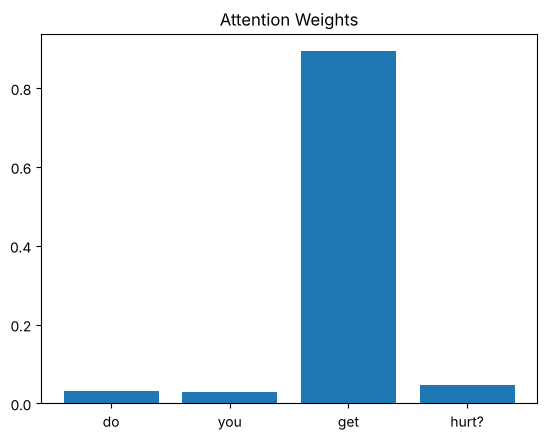

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Do you have a gender?            highest attention: 'gender' (0.99)
How old are you?                 highest attention: 'old' (0.69)
So what is your name?            highest attention: 'so' (0.94)


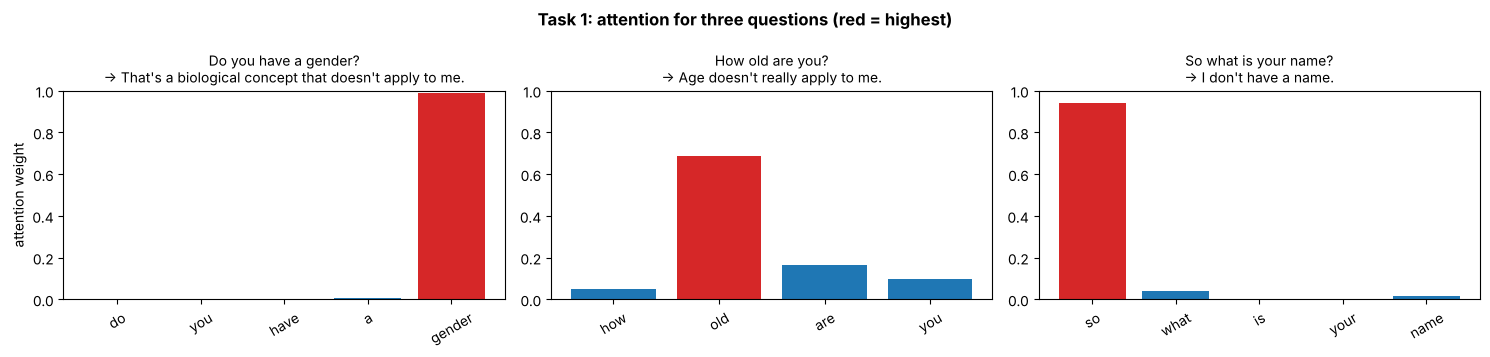

In [7]:
def attention_for(question):
    """Return the question's words, their attention weights and the predicted answer."""
    q = question.lower()
    seq = tokenizer.texts_to_sequences([q])[0]
    x = torch.tensor([seq])
    with torch.no_grad():
        logits, w = model(x)
    words = [tokenizer.index_word[t] for t in seq]
    answer = df.loc[df["answer_id"] == logits.argmax().item(), "answer"].iloc[0]
    return words, w[0].tolist(), answer


def plot_attention(questions, title):
    fig, axes = plt.subplots(1, len(questions), figsize=(5 * len(questions), 3.6))
    for ax, q in zip(axes, questions):
        words, weights, answer = attention_for(q)
        top = max(range(len(words)), key=lambda k: weights[k])
        colors = ["tab:red" if k == top else "tab:blue" for k in range(len(words))]
        ax.bar(words, weights, color=colors)
        ax.set_ylim(0, 1)
        ax.set_title(f"{q}\n-> {answer}", fontsize=10)
        ax.tick_params(axis="x", rotation=30)
        print(f"{q:32} highest attention: '{words[top]}' ({weights[top]:.2f})")
    axes[0].set_ylabel("attention weight")
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()


task1_questions = ["Do you have a gender?", "How old are you?", "So what is your name?"]
plot_attention(task1_questions, "Task 1: attention for three questions (red = highest)")

**Answer:** Mostly yes. In *"Do you have a gender?"* almost all the attention goes to **gender**, and in *"How old are you?"* the top word is **old**. These are the words that decide the answer, while common words like *do, you, are* get almost none.

The exception is *"So what is your name?"*, where the top word is **so**, not *name*. In this dataset "so" appears only in name questions, so the model learned it as a shortcut. High attention shows what the model relies on, which is not always what a human would consider important.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Do you have family?              highest attention: 'family' (0.82)
Do you have parents?             highest attention: 'parents' (0.94)


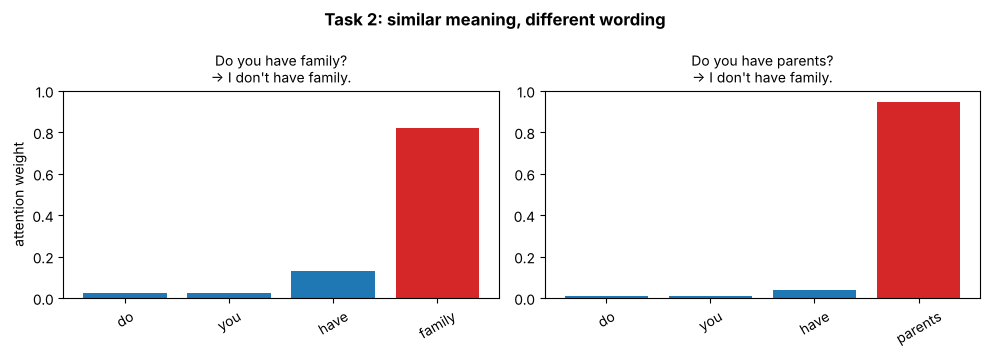

Who created you?                 highest attention: 'created' (0.47)
Who built you?                   highest attention: 'who' (0.93)


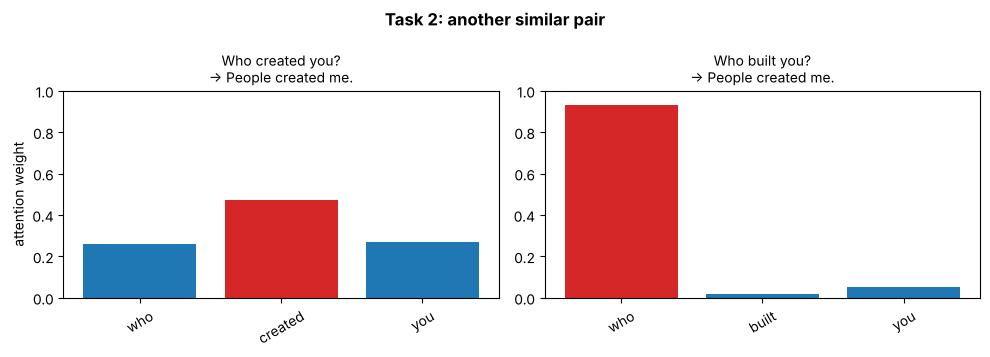

In [8]:
plot_attention(["Do you have family?", "Do you have parents?"],
               "Task 2: similar meaning, different wording")

# a second pair for comparison
plot_attention(["Who created you?", "Who built you?"],
               "Task 2: another similar pair")

**Answer:** For *"Do you have family?"* and *"Do you have parents?"* the model focuses on similar words: the key noun gets most of the attention (**family** and **parents**). For *"Who created you?"* and *"Who built you?"* the focus is different: the first spreads attention with **created** highest, while the second puts almost all of it on **who**. Both pairs still get the correct answer.

This suggests attention doesn't follow meaning directly. It learns which positions are most useful for the task from the training data. Because the RNN's hidden state at each word also carries the words before it, attention can sit on a different word and still capture the meaning.